# Installation

The following cell installs a client that interacts with our pre-release API for the new version of TabPFN. This way, no GPU is required.

Restart your runtime and rerun the *cell*, if Colab asks for it.

In [51]:
# Install sklearn
! pip install scikit-learn==1.5.2

# Install TabPFN API Client
! pip install tabpfn-client

! pip install tabpfn

# TabPFN Extensions installs optional functionalities around the TabPFN model
# These include post-hoc ensembles, interpretability tools, and more
! git clone https://github.com/PriorLabs/tabpfn-extensions
! pip install -e tabpfn-extensions
! pip install tabpfn # TabPFN, currently required by tabpfn-extensions, but not basic usage


# Install Baselines
! pip install catboost xgboost

# Install example datasets
! pip install datasets

fatal: destination path 'tabpfn-extensions' already exists and is not an empty directory.
Obtaining file:///Users/danish/MATLAB-Drive/FYP/FYP%20Master/MiskCodes/Analysis/Python/Python%20Main%20Container/Transformer/tabpfn-extensions
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tabpfn-community (pyproject.toml) ... done
  Created wheel for tabpfn-community: filename=tabpfn_community-0.0.4-0.editable-py3-none-any.whl size=11280 sha256=081f2c4a755e35dca2c044b2c0f909768f256e397e0e8b1b6e49568c33d0818e
  Stored in directory: /private/var/folders/cl/wxhg84_d06q47nm4f6nr73500000gn/T/pip-ephem-wheel-cache-4tjtyqbo/wheels/40/cb/fb/f7a318023670961cf95fda2d51d4b66bdd7272b0bef893d865
Successfully built tabpfn-community
  Attempting uninstall: tabpfn-community
    Found existing installation: tabpfn-community 0.0.4


**Now Restart the Runtime**

# Necessary Imports for the Notebook

The examples in this notebook require the following imports.
Make sure to run this cell before any other cell.




In [53]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from tabpfn import TabPFNRegressor
from sklearn.preprocessing import StandardScaler

# Main Model


In [54]:
# Load dataset
df = pd.read_csv("./Version_2_Combined_DataSet.csv")

In [55]:
pd.DataFrame(df).head()

,w1,w2,w3,wPL,DC,range
0,0.55,0.43,0.64,0.000068,FHDS_extended,220.939167
1,0.49,0.45,0.65,0.000019,US06City_extended,170.073440
2,0.94,0.83,0.85,0.000037,FHDS_extended,221.714444
3,0.15,0.96,0.94,0.000024,FUDS_extended,167.661833
4,0.65,0.12,0.50,0.000075,US06_extended,174.376322


In [56]:
X = df[['w1', 'w2', 'w3', 'wPL', 'DC']].values
y = df['range'].values

X

array([[0.55, 0.43, 0.64, 6.8e-05, 'FHDS_extended'],
       [0.49, 0.45, 0.65, 1.9e-05, 'US06City_extended'],
       [0.94, 0.83, 0.85, 3.7e-05, 'FHDS_extended'],
       ...,
       [0.27, 1.0, 0.83, 9e-05, 'FUDS_extended'],
       [0.35, 0.9, 0.01, 2.6e-05, 'US06City_extended'],
       [0.63, 0.53, 0.19, 6.6e-05, 'FUDS_extended']],
      shape=(2800, 5), dtype=object)

In [57]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.55,0.43,0.64,0.000068,FHDS_extended
1,0.49,0.45,0.65,0.000019,US06City_extended
2,0.94,0.83,0.85,0.000037,FHDS_extended
3,0.15,0.96,0.94,0.000024,FUDS_extended
4,0.65,0.12,0.5,0.000075,US06_extended


In [58]:
# extracting 4th column from X

pd.DataFrame(X[:, 4]).head()

,0
0,FHDS_extended
1,US06City_extended
2,FHDS_extended
3,FUDS_extended
4,US06_extended


In [59]:
# encoding the 4th column

X[:, 4] = pd.Categorical(X[:, 4]).codes

In [60]:
pd.Series(X[:, 4]).value_counts()

0    400
4    400
1    400
6    400
3    400
2    400
5    400
Name: count, dtype: int64

In [61]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.55,0.43,0.64,0.000068,0
1,0.49,0.45,0.65,0.000019,4
2,0.94,0.83,0.85,0.000037,0
3,0.15,0.96,0.94,0.000024,1
4,0.65,0.12,0.5,0.000075,6


In [62]:
# comparing the original and encoded values and making a df which contains the original and encoded values for each unique value

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates()

# make a CSV for this DF which is printed

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates().to_csv('Encoded_DC.csv', index=False)


In [63]:
# Split data into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [64]:
model = TabPFNRegressor()

In [65]:
# Fit the model on the training data
model.fit(X_train, y_train)

TabPFNRegressor()

In [66]:
# Predict on both training and testing sets
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [67]:
# Evaluate model performance using RMSE and R²
train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
train_r2 = r2_score(y_train, train_preds)
test_r2 = r2_score(y_test, test_preds)

In [68]:
print("Training RMSE: {:.2f}".format(train_rmse))
print("Test RMSE: {:.2f}".format(test_rmse))
print("Training R²: {:.2f}".format(train_r2))
print("Test R²: {:.2f}".format(test_r2))

Training RMSE: 0.24
Test RMSE: 0.56
Training R²: 1.00
Test R²: 1.00


In [69]:
# Example prediction using the first row of the dataset
example_input = X[0:1]
example_prediction = model.predict(example_input)
print("\nExample prediction:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Example prediction:
Input features:
 [[0.55 0.43 0.64 6.8e-05 0]]
Predicted range: 221.05
Actual range: 220.94


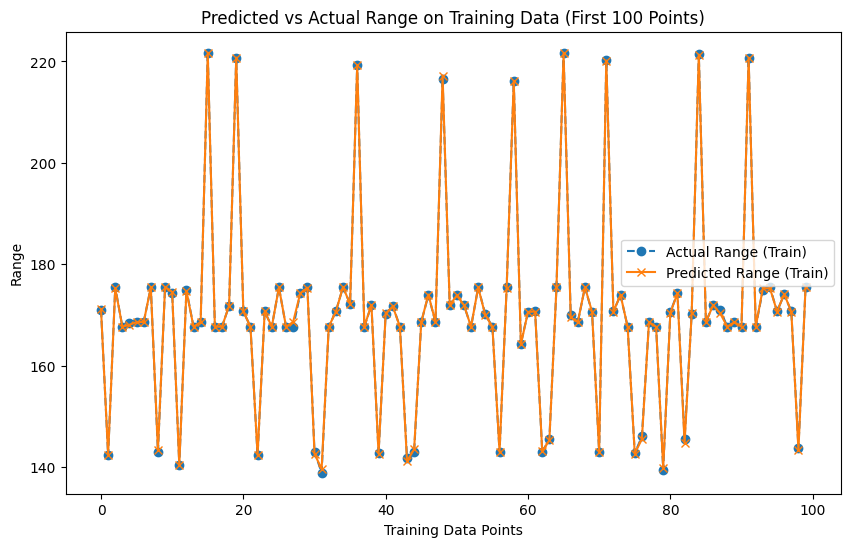

In [70]:
# Plot predicted vs. actual values for the first 100 training data points
plt.figure(figsize=(10, 6))
plt.plot(y_train[:100], label='Actual Range (Train)', marker='o', linestyle='--')
plt.plot(train_preds[:100], label='Predicted Range (Train)', marker='x', linestyle='-')
plt.xlabel('Training Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Training Data (First 100 Points)')
plt.legend()
plt.show()

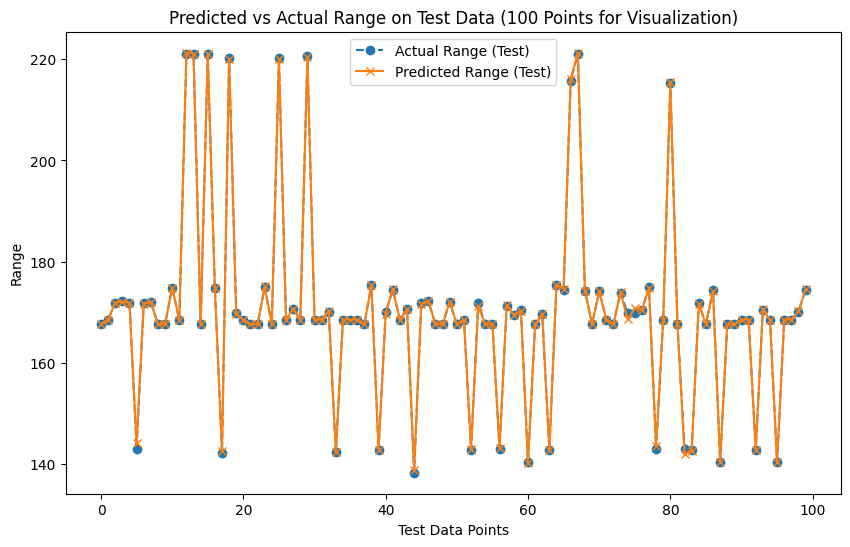

In [71]:
# Plot predicted vs. actual values for test data
plt.figure(figsize=(10, 6))
plt.plot(y_test[:100], label='Actual Range (Test)', marker='o', linestyle='--')
plt.plot(test_preds[:100], label='Predicted Range (Test)', marker='x', linestyle='-')
plt.xlabel('Test Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Test Data (100 Points for Visualization)')
plt.legend()
plt.show()

In [72]:
dc_categories = pd.Categorical(df['DC']).categories

In [73]:
def predict_range(w1, w2, w3, wPL, DC):

    input_sample = np.array([[w1, w2, w3, wPL, DC]])
    # Predict using the trained TabPFN regressor.
    prediction = model.predict(input_sample)
    return prediction[0]

In [74]:
# -------------------------------
# Test the predict_range function with the first row of the dataset
# -------------------------------
example_input = X[0:1]  # First row (already encoded)
example_prediction = model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct example prediction from model:
Input features:
 [[0.55 0.43 0.64 6.8e-05 0]]
Predicted range: 221.05
Actual range: 220.94


In [75]:
raw_DC_value = df['DC'].iloc[0]

print("Raw DC value:", raw_DC_value)

Raw DC value: FHDS_extended


In [76]:
# converting raw dc to numeric, ie comparing string with encoded

pd.Categorical([raw_DC_value], categories=dc_categories).codes[0]

print("Encoded DC value:", pd.Categorical([raw_DC_value], categories=dc_categories).codes[0])

raw_DC_value = pd.Categorical([raw_DC_value], categories=dc_categories).codes[0]

print("Encoded DC value:", raw_DC_value)

Encoded DC value: 0
Encoded DC value: 0


In [77]:
pred_from_func = predict_range(
    float(example_input[0][0]),
    float(example_input[0][1]),
    float(example_input[0][2]),
    float(example_input[0][3]),
    raw_DC_value
)
print("\nExample prediction using predict_range function:")
print("Predicted range: {:.2f}".format(pred_from_func))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Example prediction using predict_range function:
Predicted range: 221.05
Actual range: 220.94


In [78]:
import pickle

In [79]:
# -------------------------------
# Save the trained model using pickle
# -------------------------------
with open("./Models/tabpfn_regressor_local.pkl", "wb") as f:
    pickle.dump(model, f)
print("Model saved to tabpfn_regressor_local.pkl")

Model saved to tabpfn_regressor_local.pkl


In [80]:
# -------------------------------
# Load the model from disk
# -------------------------------
with open("./Models/tabpfn_regressor_local.pkl", "rb") as f:
    loaded_model = pickle.load(f)
print("Model loaded from tabpfn_regressor_local.pkl")

Model loaded from tabpfn_regressor_local.pkl


In [81]:
example_prediction = loaded_model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct example prediction from model:
Input features:
 [[0.55 0.43 0.64 6.8e-05 0]]
Predicted range: 221.05
Actual range: 220.94


In [82]:
example_prediction = loaded_model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct example prediction from model:
Input features:
 [[0.55 0.43 0.64 6.8e-05 0]]
Predicted range: 221.05
Actual range: 220.94


In [83]:
# Evaluate the loaded model on the test set to verify it works the same
loaded_test_preds = loaded_model.predict(X_test)
loaded_test_rmse = np.sqrt(mean_squared_error(y_test, loaded_test_preds))
loaded_test_r2   = r2_score(y_test, loaded_test_preds)

print("Loaded Model Test RMSE: {:.2f}".format(loaded_test_rmse))
print("Loaded Model Test R²: {:.2f}".format(loaded_test_r2))


Loaded Model Test RMSE: 0.56
Loaded Model Test R²: 1.00


In [84]:
def predict_range_model(model_instance, w1, w2, w3, wPL, DC):
    """
    Predict the range for a single new sample.
    The DC value is encoded using the original dataset's unique categories.
    """
    # Encode the provided DC value to its corresponding numeric code
    dc_code  = pd.Categorical([DC], categories=dc_categories).codes[0]
    # Create a 2D array for the new sample
    print(w1, w2, w3, wPL, dc_code)
    input_sample = np.array([[w1, w2, w3, wPL, dc_code]])
    # Use the provided model instance to predict
    prediction = model_instance.predict(input_sample)
    return prediction[0]

In [85]:
example_input = X[0:1]  # Already encoded sample from the original dataset
raw_DC_value = df['DC'].iloc[0]  # Original DC value

In [86]:
# Direct prediction from the loaded model for comparison
direct_prediction = loaded_model.predict(example_input)[0]

In [87]:
print('Raw DC', raw_DC_value)

Raw DC FHDS_extended


In [88]:
# Prediction using our helper function
func_prediction = predict_range_model(
    loaded_model,
    float(example_input[0][0]),
    float(example_input[0][1]),
    float(example_input[0][2]),
    float(example_input[0][3]),
    raw_DC_value
)

0.55 0.43 0.64 6.8e-05 0


In [89]:
print("\nDirect prediction from loaded model:")
print("Predicted range: {:.2f}".format(direct_prediction))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct prediction from loaded model:
Predicted range: 221.05
Actual range: 220.94


In [90]:
print("\nPrediction using predict_range_model function:")
print("Predicted range: {:.2f}".format(func_prediction))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Prediction using predict_range_model function:
Predicted range: 221.05
Actual range: 220.94


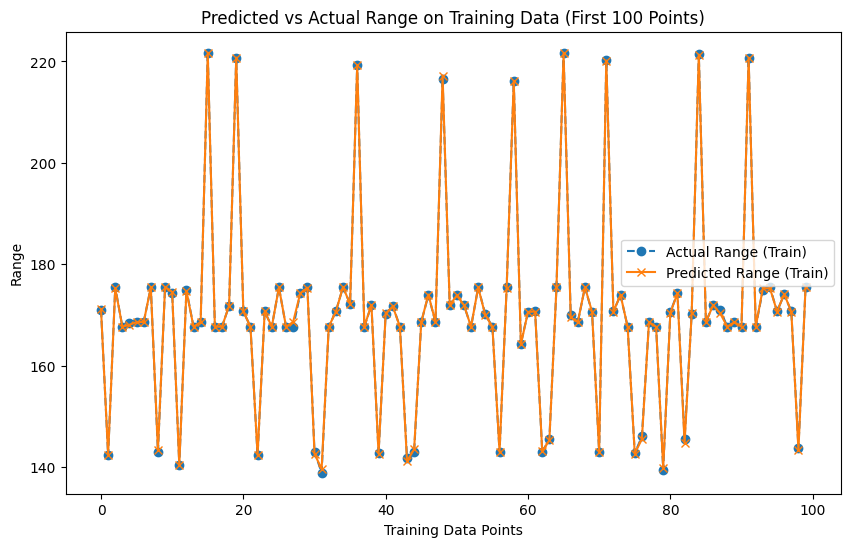

In [91]:
# -------------------------------
# Plot predicted vs. actual values for training data (first 100 points)
# -------------------------------
plt.figure(figsize=(10, 6))
plt.plot(y_train[:100], label='Actual Range (Train)', marker='o', linestyle='--')
plt.plot(train_preds[:100], label='Predicted Range (Train)', marker='x', linestyle='-')
plt.xlabel('Training Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Training Data (First 100 Points)')
plt.legend()
plt.show()

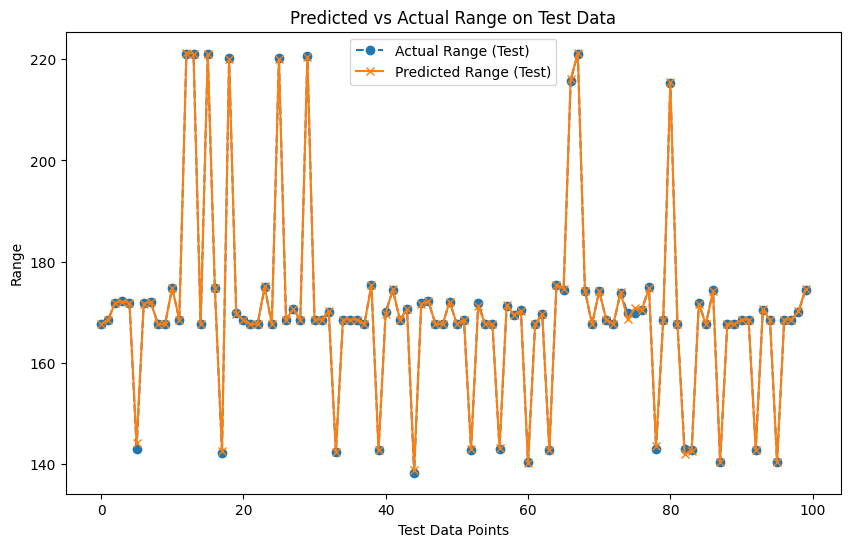

In [92]:
# -------------------------------
# Plot predicted vs. actual values for test data
# -------------------------------
plt.figure(figsize=(10, 6))
plt.plot(y_test[:100], label='Actual Range (Test)', marker='o', linestyle='--')
plt.plot(test_preds[:100], label='Predicted Range (Test)', marker='x', linestyle='-')
plt.xlabel('Test Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Test Data')
plt.legend()
plt.show()

In [93]:
! pip install scikit-optimize

In [94]:
from skopt import gp_minimize
from skopt.space import Real
from skopt.callbacks import DeltaYStopper
from skopt.utils import use_named_args
from functools import partial

In [95]:
# -------------------------------
# Define the EarlyStopper callback class
# -------------------------------
class EarlyStopper:
    def __init__(self, delta=0.01, patience=40):
        """
        delta: Minimum improvement required (in objective value) to reset the counter.
        patience: Number of iterations with no sufficient improvement before stopping.
        """
        self.delta = delta
        self.patience = patience
        self.best = None
        self.counter = 0

    def __call__(self, res):
        current_best = min(res.func_vals)  # Note: lower is better (we're minimizing negative prediction)
        if self.best is None or current_best < self.best - self.delta:
            self.best = current_best
            self.counter = 0
        else:
            self.counter += 1

        print(f"EarlyStopper: counter = {self.counter}, best objective = {-self.best:.2f}")
        if self.counter >= self.patience:
            print("Early stopping triggered.")
            return True  # Returning True stops the optimization
        return False


In [96]:
# -------------------------------
# Define the objective function for minimization
# -------------------------------
def objective_function(params, x5):
    x1, x2, x3, x4 = params
    # Round values for consistency
    x1 = round(x1, 2)
    x2 = round(x2, 2)
    x3 = round(x3, 2)
    x4 = round(x4, 8)

    # Here, predict_range is assumed to be your prediction function which takes inputs:
    # w1, w2, w3, wPL, and DC (here, x5 is used as the encoded DC value).
    # We return the negative of the predicted range since we wish to maximize it.
    return -predict_range(x1, x2, x3, x4, x5)

# -------------------------------
# Define a simple progress callback (optional)
# -------------------------------
def print_progress(res):
    iteration = len(res.func_vals)
    current_best = -min(res.func_vals)
    current_params = res.x_iters[-1]
    print(f"Iteration {iteration}: Current best predicted range = {current_best:.2f}, Latest params = {current_params}")

# -------------------------------
# Bayesian Optimization Loop
# -------------------------------
# Define the search space for x1, x2, x3, and x4
space = [
    Real(0.0, 1.0, name='x1'),
    Real(0.0, 1.0, name='x2'),
    Real(0.0, 1.0, name='x3'),
    Real(0.0, 0.0001, name='x4')
]

# Initialize a dictionary to store the optimal results for each x5
optimal_results = {}

In [ ]:
# Loop over each fixed x5 value from 0 to 6
for x5_value in range(7):
    print(f"\nOptimizing for x5 = {x5_value}...")

    # Create a version of the objective function with x5 fixed
    fixed_obj = partial(objective_function, x5=x5_value)

    # Create a new EarlyStopper instance for each optimization run
    early_stopper = EarlyStopper(delta=0.01, patience=40)

    # Run Bayesian Optimization with callbacks
    result = gp_minimize(
        fixed_obj,
        space,
        n_calls=300,
        n_initial_points=20,
        acq_func='EI',
        random_state=42,
        callback=[print_progress, early_stopper]
    )

    best_x1, best_x2, best_x3, best_x4 = result.x
    optimal_range = -result.fun  # Reverse the negative sign

    optimal_results[x5_value] = {
        "x1": round(best_x1, 2),
        "x2": round(best_x2, 2),
        "x3": round(best_x3, 2),
        "x4": round(best_x4, 6),
        "optimal_range": round(optimal_range, 2)
    }

# -------------------------------
# Print the optimal results for each x5 value
# -------------------------------
for x5_value, results in optimal_results.items():
    print(f"\nFor x5 = {x5_value}:")
    print(f"  Optimal inputs: x1 = {results['x1']:.2f}, x2 = {results['x2']:.2f}, x3 = {results['x3']:.2f}, x4 = {results['x4']:.6f}")
    print(f"  Maximum predicted range: {results['optimal_range']:.2f}")


Optimizing for x5 = 0...
Iteration 1: Current best predicted range = 187.49, Latest params = [0.7965429868602331, 0.18343478986616382, 0.7796910002727695, 5.968501579464871e-05]
EarlyStopper: counter = 0, best objective = 187.49
Iteration 2: Current best predicted range = 187.49, Latest params = [0.44583275285359125, 0.09997491581800291, 0.45924889196586727, 3.337086111390219e-05]
EarlyStopper: counter = 1, best objective = 187.49
Iteration 3: Current best predicted range = 188.90, Latest params = [0.1428668179219408, 0.650888472948853, 0.05641157902710027, 7.21998772266825e-05]
EarlyStopper: counter = 0, best objective = 188.90
Iteration 4: Current best predicted range = 188.90, Latest params = [0.9385527090157504, 0.0007787658410143285, 0.9922115592912177, 6.174815096277167e-05]
EarlyStopper: counter = 1, best objective = 188.90
Iteration 5: Current best predicted range = 188.90, Latest params = [0.611653160488281, 0.007066305219717408, 0.02306242504141576, 5.247746602583893e-05]
Ea

/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [1.0, 1.0, 0.0, 0.0001] before, using random point [0.35759446894003494, 0.783186983123679, 0.4560798083147427, 6.681877129906861e-05]
  warnings.warn(


Iteration 22: Current best predicted range = 192.31, Latest params = [0.35759446894003494, 0.783186983123679, 0.4560798083147427, 6.681877129906861e-05]
EarlyStopper: counter = 1, best objective = 192.31


/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [1.0, 1.0, 0.0, 0.0001] before, using random point [0.8644301160931821, 0.738799889399012, 0.29671256177556765, 1.0920820043550264e-05]
  warnings.warn(


Iteration 23: Current best predicted range = 192.31, Latest params = [0.8644301160931821, 0.738799889399012, 0.29671256177556765, 1.0920820043550264e-05]
EarlyStopper: counter = 2, best objective = 192.31
Iteration 24: Current best predicted range = 192.31, Latest params = [0.13238700493847635, 0.9970564877357007, 0.05599084308871084, 9.47084445176689e-05]
EarlyStopper: counter = 3, best objective = 192.31


/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [1.0, 1.0, 0.0, 0.0001] before, using random point [0.7101054472272881, 0.4831805322291315, 0.14075657487148255, 4.849103938567768e-06]
  warnings.warn(


... (63 outputs left out)

/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [1.0, 1.0, 0.0, 0.0001] before, using random point [0.4425246434004084, 0.06615981786131254, 0.4261118195429069, 2.9511025701231293e-05]
  warnings.warn(


Iteration 27: Current best predicted range = 145.97, Latest params = [0.4425246434004084, 0.06615981786131254, 0.4261118195429069, 2.9511025701231293e-05]
EarlyStopper: counter = 1, best objective = 145.97
Iteration 28: Current best predicted range = 145.97, Latest params = [0.0, 1.0, 0.0, 0.0001]
EarlyStopper: counter = 2, best objective = 145.97
Iteration 29: Current best predicted range = 145.97, Latest params = [0.8953075430221864, 0.4961571268964296, 0.8325637619803417, 0.0001]
EarlyStopper: counter = 3, best objective = 145.97
Iteration 30: Current best predicted range = 145.97, Latest params = [0.03847625082134715, 0.9352657107993926, 0.5542202401572023, 0.0]
EarlyStopper: counter = 4, best objective = 145.97
Iteration 31: Current best predicted range = 145.97, Latest params = [0.6935948272799783, 0.9623207799440506, 0.0, 0.0001]
EarlyStopper: counter = 5, best objective = 145.97
Iteration 32: Current best predicted range = 145.97, Latest params = [0.0, 0.0, 0.0, 0.0001]
EarlySt

/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [1.0, 1.0, 0.0, 0.0001] before, using random point [0.9694776261998793, 0.5063949579345568, 0.14899854956641648, 5.057134376170184e-05]
  warnings.warn(


Iteration 34: Current best predicted range = 145.98, Latest params = [0.9694776261998793, 0.5063949579345568, 0.14899854956641648, 5.057134376170184e-05]
EarlyStopper: counter = 1, best objective = 145.98
Iteration 35: Current best predicted range = 145.98, Latest params = [1.0, 1.0, 0.14031979417987595, 0.0001]
EarlyStopper: counter = 2, best objective = 145.98
Iteration 36: Current best predicted range = 145.98, Latest params = [1.0, 0.2908824329545094, 0.0, 0.0001]
EarlyStopper: counter = 3, best objective = 145.98
Iteration 37: Current best predicted range = 146.15, Latest params = [0.8840155951656088, 0.8387703200044797, 0.0, 9.495343541386147e-05]
EarlyStopper: counter = 0, best objective = 146.15
Iteration 38: Current best predicted range = 146.15, Latest params = [1.0, 1.0, 0.0, 8.883322848961049e-05]
EarlyStopper: counter = 1, best objective = 146.15
Iteration 39: Current best predicted range = 146.15, Latest params = [0.7680669643786012, 0.7387174469818989, 0.0, 9.62453832320

In [ ]:
# saving optimal range and weights to a CSV file

for x5_value, results in optimal_results.items():
    pd.DataFrame({
        'w1': [results['x1']],
        'w2': [results['x2']],
        'w3': [results['x3']],
        'wPL': [f"{results['x4']}"],
        'DC': [x5_value],
        'DC_Name': [dc_categories[x5_value]],
        'Range': [results['optimal_range']]
    }).to_csv('/content/Optimised_Bayesian_Values_Range.csv', mode='a', header=False, index=False)
